# Predição da qualidade de vinhos tintos e brancos

Análise comparativa entre regressão linear e Random Forest.

Os cálculos ficam nos módulos de `src`. Este notebook apenas conduz a leitura, a análise e a avaliação.

Fonte dos dados: [Wine Quality na UCI](https://archive.ics.uci.edu/dataset/186/wine+quality).

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data_preprocessing import (
    combine_wines,
    duplicate_count,
    iqr_outlier_report,
    load_raw,
    missing_value_report,
    remove_duplicates,
    split_train_test,
)
from src.evaluate_models import cross_validate_model, evaluate_regression
from src.exploratory_analysis import (
    attribute_dictionary,
    correlation_with_target,
    descriptive_statistics,
    quality_distribution,
)
from src.train_models import build_models, train_models
from src.visualizations import (
    save_boxplots,
    save_correlation_heatmap,
    save_prediction_plots,
    save_quality_distribution,
)
from src.exploratory_analysis import correlation_matrix

FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

## Compreensão dos dados

A base oficial traz 11 atributos físico-químicos e a nota sensorial `quality`. O atributo `type` é acrescentado aqui: branco = 0 e tinto = 1.

In [2]:
red, white = load_raw()
combined = combine_wines(red, white)
clean = remove_duplicates(combined)

print("tintos:", red.shape)
print("brancos:", white.shape)
print("combinados:", combined.shape)
print("ausentes:", int(missing_value_report(combined).sum()))
print("duplicatas exatas:", duplicate_count(combined))
print("após remoção:", clean.shape)
print(clean["type"].value_counts().rename({0: "branco", 1: "tinto"}))
attribute_dictionary()

tintos: (1599, 12)
brancos: (4898, 12)
combinados: (6497, 13)
ausentes: 0
duplicatas exatas: 1177
após remoção: (5320, 13)
type
branco    3961
tinto     1359
Name: count, dtype: int64


,attribute,role,description
0,fixed acidity,preditor,Acidez fixa medida em teste físico-químico.
1,volatile acidity,preditor,Acidez volátil medida em teste físico-químico.
2,citric acid,preditor,Ácido cítrico medido em teste físico-químico.
3,residual sugar,preditor,Açúcar residual medido em teste físico-químico.
4,chlorides,preditor,Cloretos medidos em teste físico-químico.
5,free sulfur dioxide,preditor,Dióxido de enxofre livre medido em teste físic...
6,total sulfur dioxide,preditor,Dióxido de enxofre total medido em teste físic...
7,density,preditor,Densidade medida em teste físico-químico.
8,pH,preditor,pH medido em teste físico-químico.
9,sulphates,preditor,Sulfatos medidos em teste físico-químico.


## Análise exploratória

As duplicatas exatas são removidas. Os outliers identificados pelo intervalo interquartil permanecem na base.

In [3]:
descriptive_statistics(clean)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,5320.0,7.215179,1.319671,3.80000,6.4000,7.00000,7.70000,15.90000
volatile acidity,5320.0,0.344130,0.168248,0.08000,0.2300,0.30000,0.41000,1.58000
citric acid,5320.0,0.318494,0.147157,0.00000,0.2400,0.31000,0.40000,1.66000
residual sugar,5320.0,5.048477,4.500180,0.60000,1.8000,2.70000,7.50000,65.80000
chlorides,5320.0,0.056690,0.036863,0.00900,0.0380,0.04700,0.06600,0.61100
free sulfur dioxide,5320.0,30.036654,17.805045,1.00000,16.0000,28.00000,41.00000,289.00000
total sulfur dioxide,5320.0,114.109023,56.774223,6.00000,74.0000,116.00000,153.25000,440.00000
density,5320.0,0.994535,0.002966,0.98711,0.9922,0.99465,0.99677,1.03898
pH,5320.0,3.224664,0.160379,2.72000,3.1100,3.21000,3.33000,4.01000
sulphates,5320.0,0.533357,0.149743,0.22000,0.4300,0.51000,0.60000,2.00000


In [4]:
quality_distribution(clean)

,type,quality,count
0,0,3,20
1,0,4,153
2,0,5,1175
3,0,6,1788
4,0,7,689
5,0,8,131
6,0,9,5
7,1,3,10
8,1,4,53
9,1,5,577


In [5]:
outlier_table, outlier_rows = iqr_outlier_report(clean)
print("registros com algum outlier:", int(outlier_rows.sum()))
outlier_table

registros com algum outlier: 1094


,attribute,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_proportion
0,fixed acidity,6.4000,7.70000,1.30000,4.450000e+00,9.650000,304,0.057143
1,volatile acidity,0.2300,0.41000,0.18000,-4.000000e-02,0.680000,279,0.052444
2,citric acid,0.2400,0.40000,0.16000,-5.551115e-17,0.640000,143,0.026880
3,residual sugar,1.8000,7.50000,5.70000,-6.750000e+00,16.050000,141,0.026504
4,chlorides,0.0380,0.06600,0.02800,-4.000000e-03,0.108000,237,0.044549
5,free sulfur dioxide,16.0000,41.00000,25.00000,-2.150000e+01,78.500000,44,0.008271
6,total sulfur dioxide,74.0000,153.25000,79.25000,-4.487500e+01,272.125000,10,0.001880
7,density,0.9922,0.99677,0.00457,9.853450e-01,1.003625,3,0.000564
8,pH,3.1100,3.33000,0.22000,2.780000e+00,3.660000,49,0.009211
9,sulphates,0.4300,0.60000,0.17000,1.750000e-01,0.855000,163,0.030639


In [6]:
correlation_with_target(clean)

,attribute,correlation_with_quality
0,alcohol,0.469422
1,density,-0.326434
2,volatile acidity,-0.265205
3,chlorides,-0.202137
4,type,-0.114809
5,citric acid,0.097954
6,fixed acidity,-0.080092
7,residual sugar,-0.056830
8,free sulfur dioxide,0.054002
9,total sulfur dioxide,-0.050296


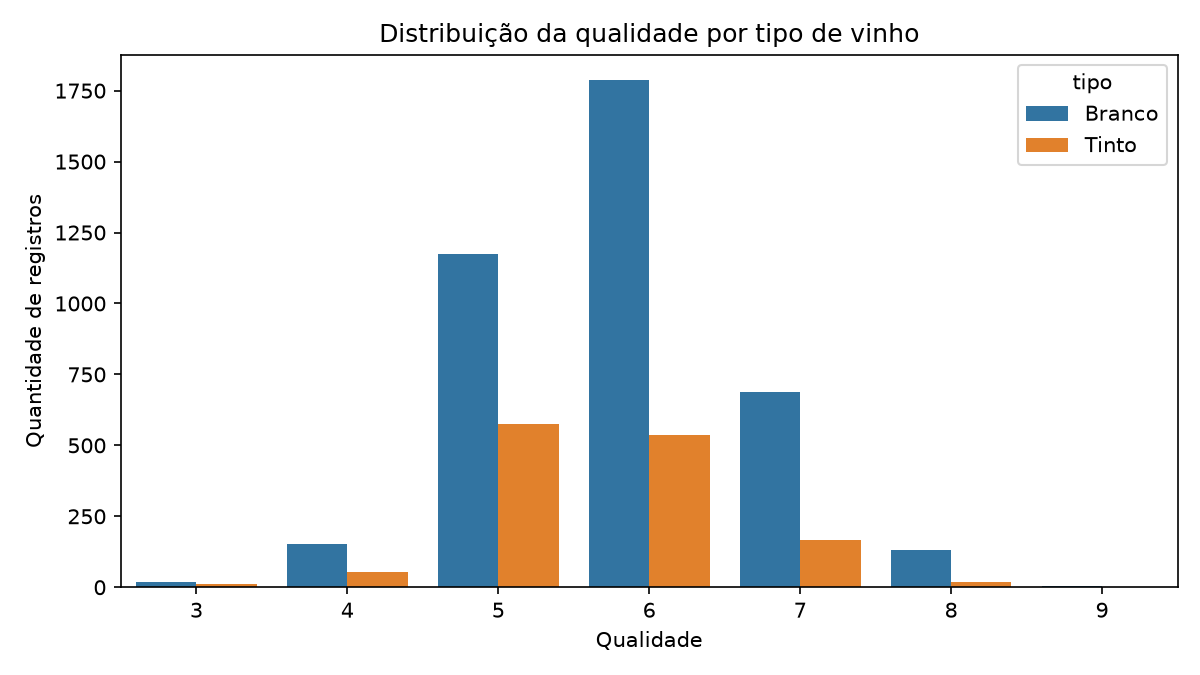

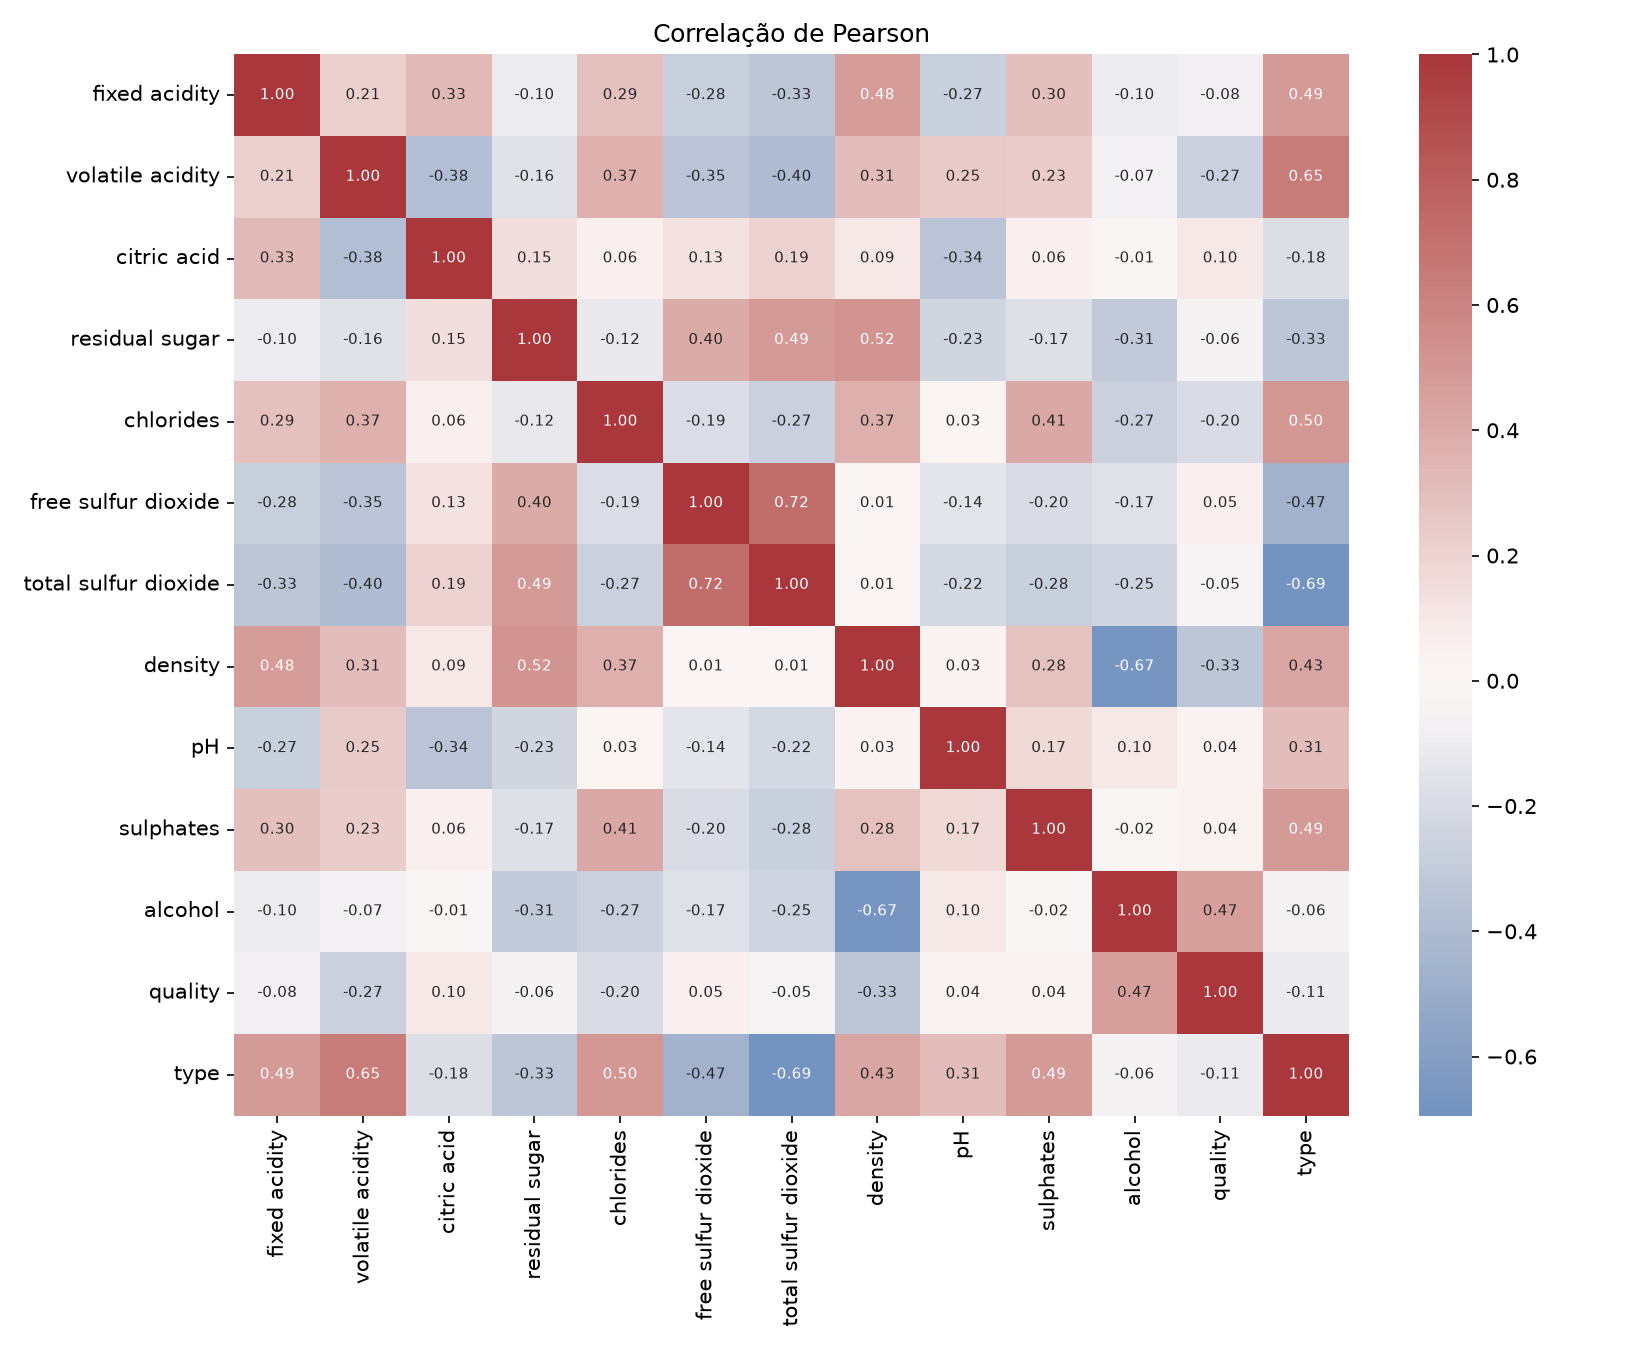

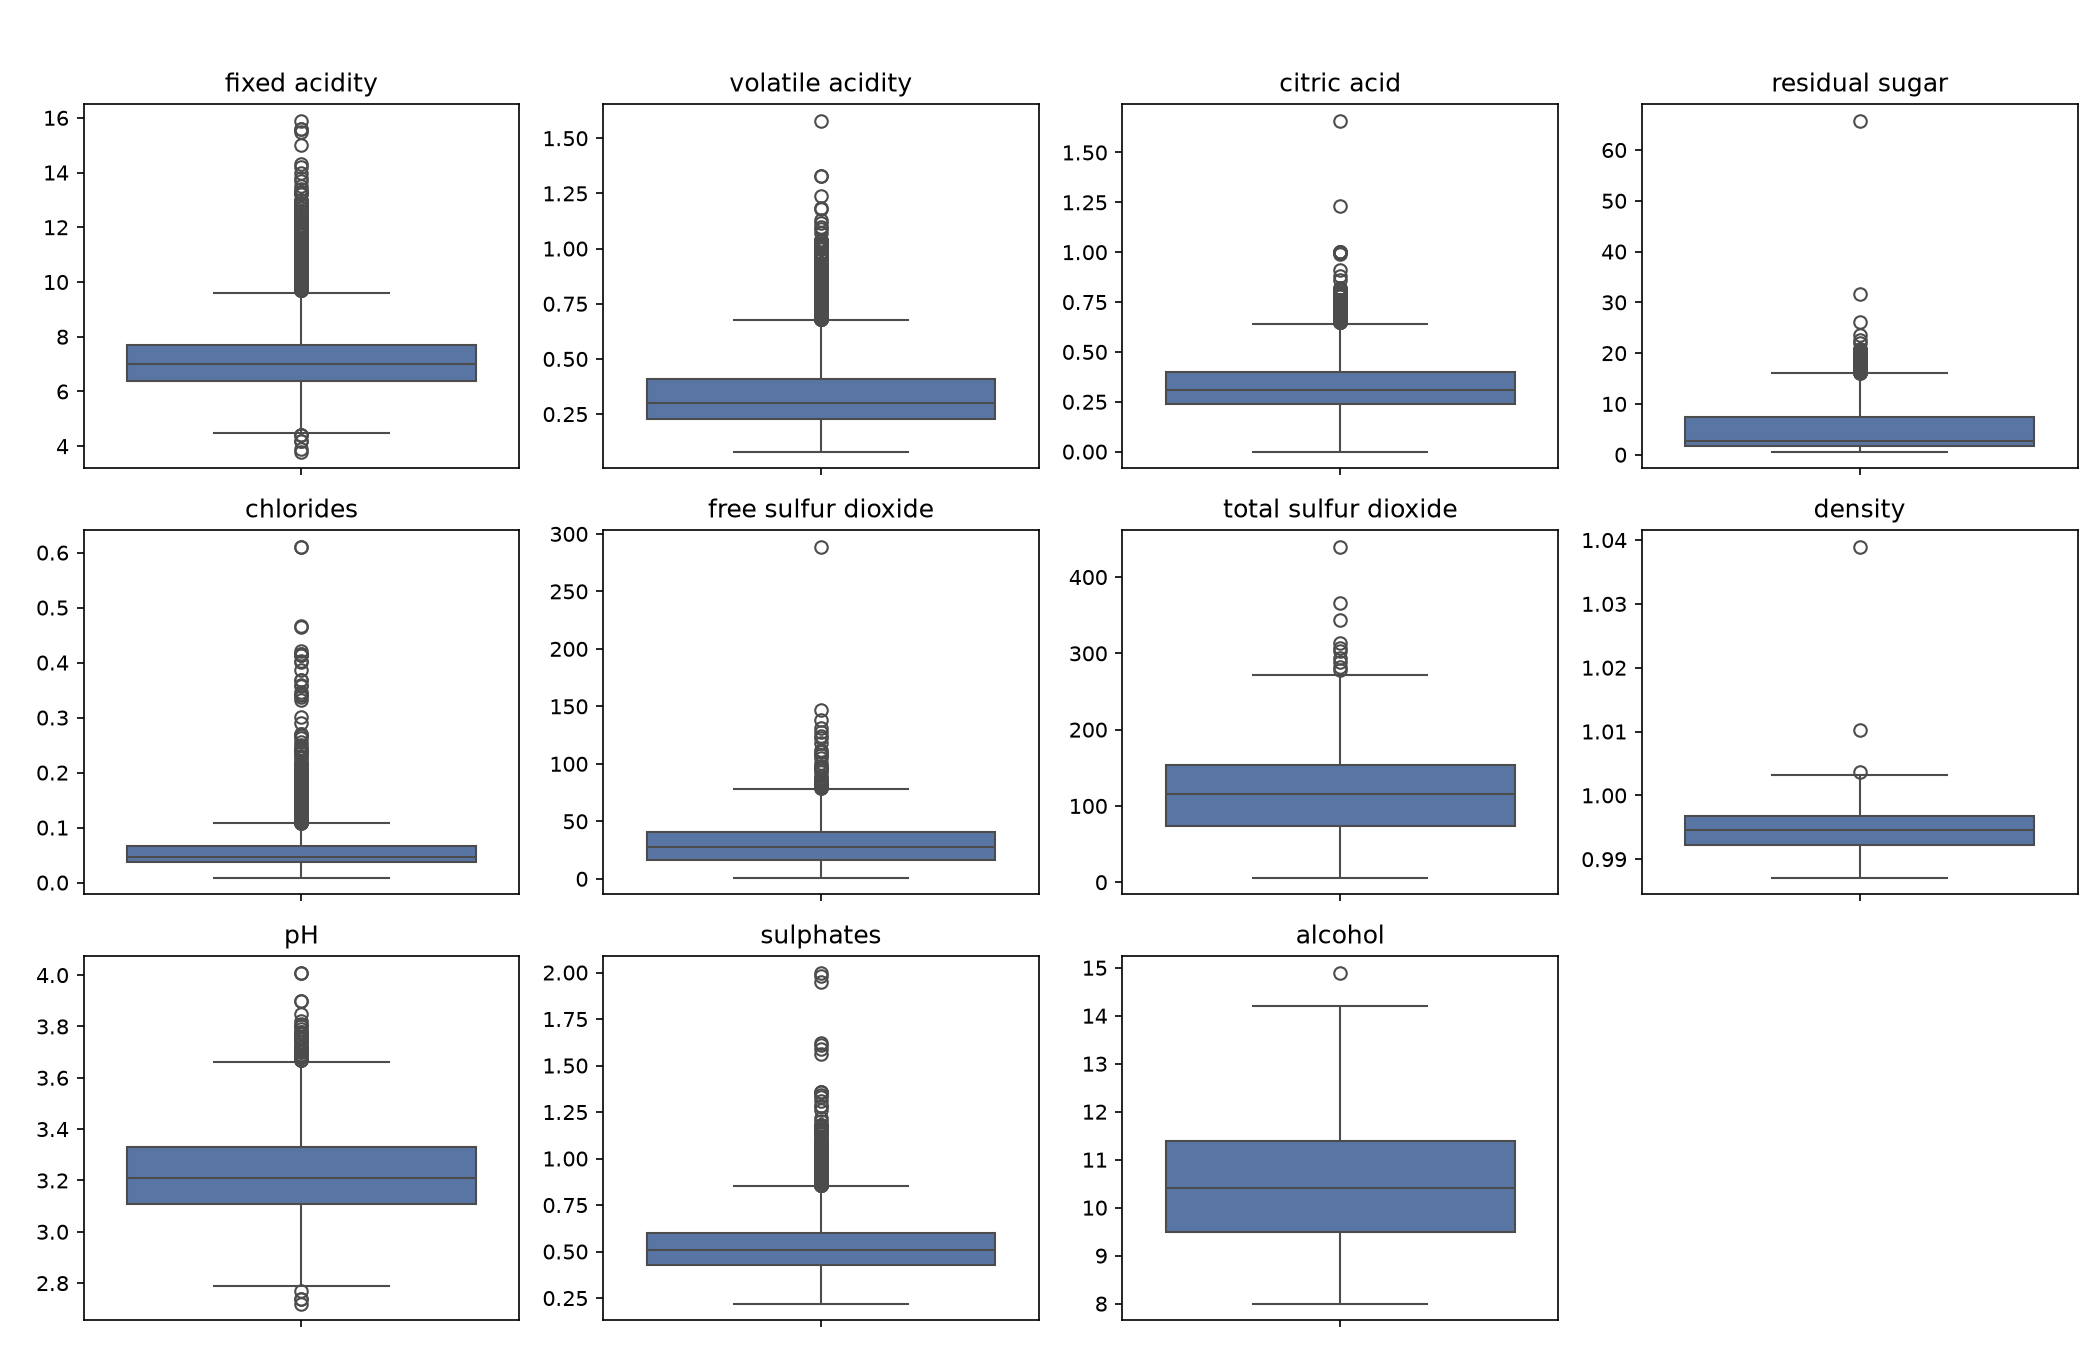

In [7]:
quality_path = save_quality_distribution(clean, FIGURES / "quality_by_type.png")
heatmap_path = save_correlation_heatmap(correlation_matrix(clean), FIGURES / "correlation_heatmap.png")
boxplot_path = save_boxplots(clean, FIGURES / "boxplots_physicochemical.png")
display(Image(filename=str(quality_path)))
display(Image(filename=str(heatmap_path)))
display(Image(filename=str(boxplot_path)))

## Modelagem e avaliação

A divisão é 80% para treino e 20% para teste, com `random_state=42`. Os dois modelos recebem essa mesma divisão. A padronização ocorre dentro do pipeline. A validação cruzada de cinco partições usa somente o treino.

treino: 4256 teste: 1064


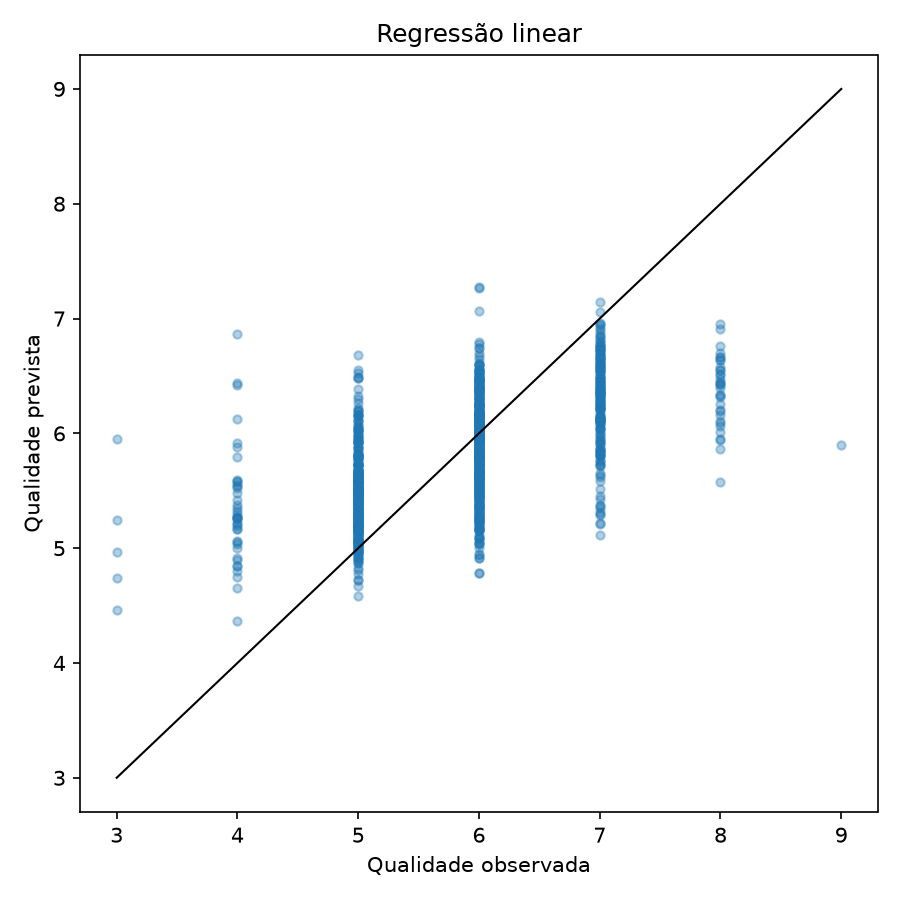

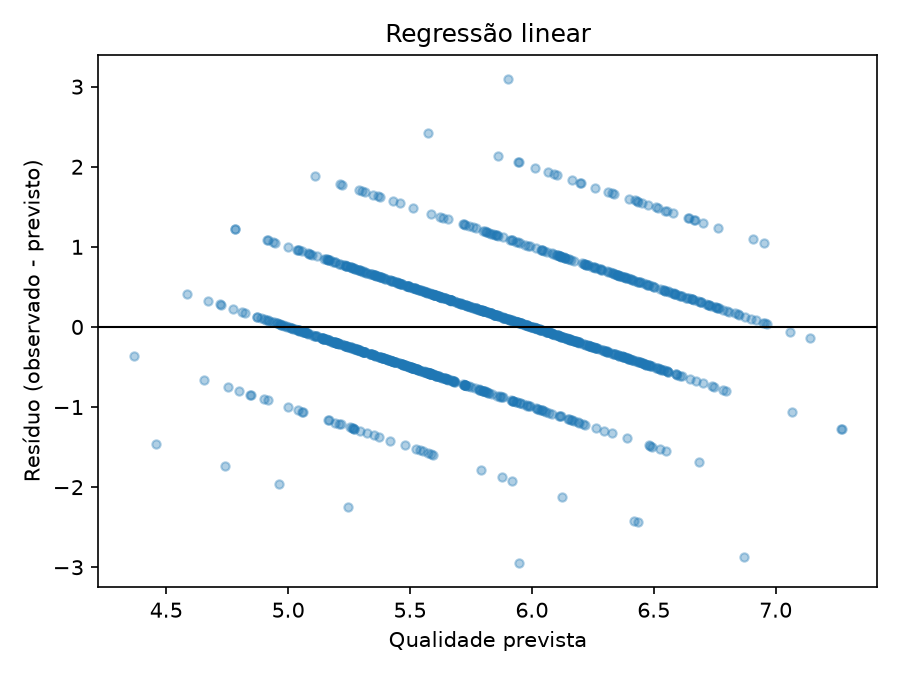

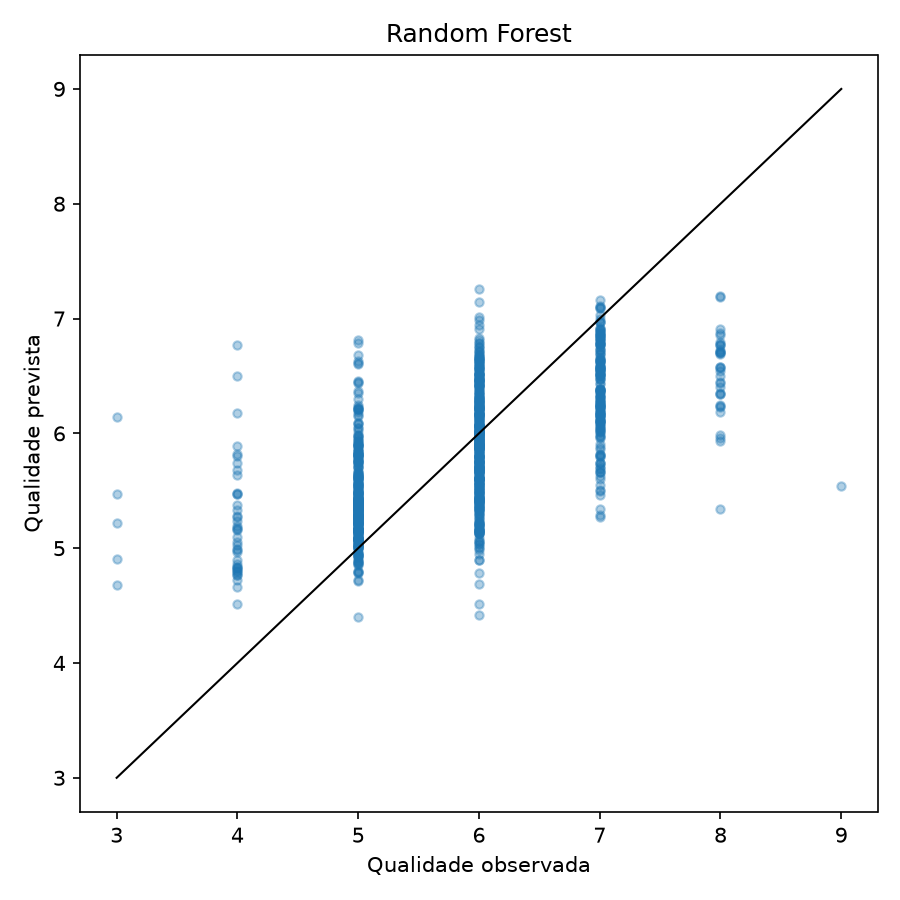

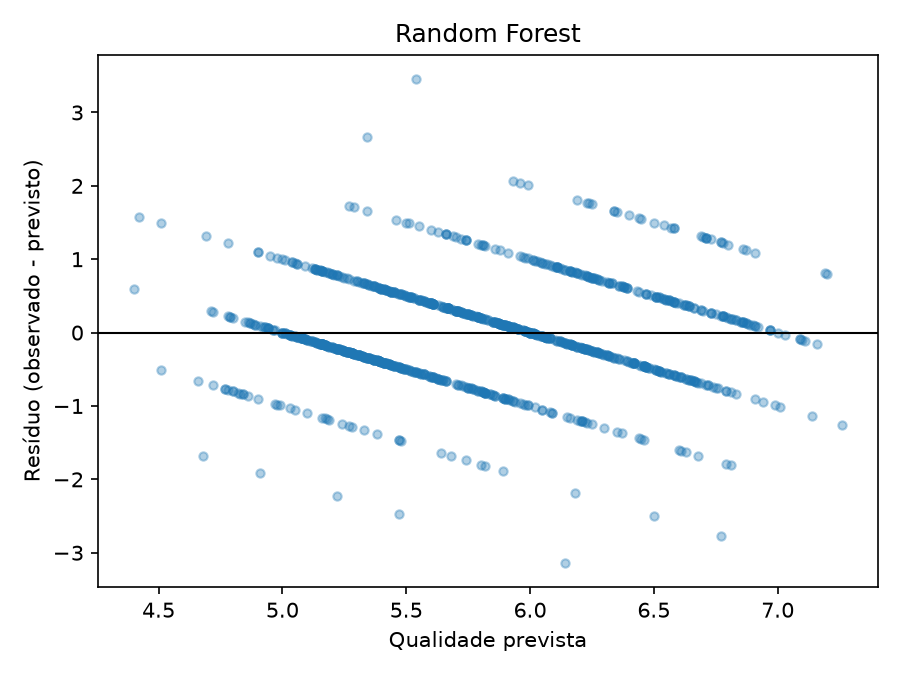

,mae,mse,rmse,r2,model
0,0.555705,0.518021,0.719736,0.345829,linear_regression
1,0.532284,0.485096,0.696489,0.387406,random_forest


In [8]:
features_train, features_test, target_train, target_test = split_train_test(clean)
print("treino:", len(features_train), "teste:", len(features_test))

models = build_models()
cv_table = pd.DataFrame(
    [
        cross_validate_model(name, pipeline, features_train, target_train)
        for name, pipeline in models.items()
    ]
)
fitted = train_models(models, features_train, target_train)

rows = []
for name, pipeline in fitted.items():
    metrics, predicted = evaluate_regression(pipeline, features_test, target_test)
    metrics["model"] = name
    rows.append(metrics)
    plots = save_prediction_plots(name, target_test.to_numpy(), predicted, FIGURES)
    display(Image(filename=str(plots["pred_vs_actual"])))
    display(Image(filename=str(plots["residuals"])))

pd.DataFrame(rows)

In [9]:
cv_table[["model", "mae_mean", "mae_std", "r2_mean", "r2_std"]]

,model,mae_mean,mae_std,r2_mean,r2_std
0,linear_regression,0.569990,0.023466,0.291459,0.028769
1,random_forest,0.536699,0.025363,0.363388,0.032904
